Устанавливаем пакеты:

In [ ]:
# %pip install numpy
# %pip install pandas
# %pip install seaborn
# %pip install networkx
# %pip install scapy
# %pip install scipy
# %pip install tqdm
# %pip install ipywidgets

Импорт библиотек:

In [1]:
# Стандартные библиотеки для работы с файлами, временем, математикой и структурами данных
import os
import time
import math
import warnings
from pathlib import Path
from collections import Counter, defaultdict

# Библиотеки для анализа данных, статистики, графов и визуализации
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import networkx as nx

# Инструменты для отслеживания прогресса и парсинга сетевого трафика (PCAP)
from tqdm import tqdm
from scapy.all import *

# Настройка отображения таблиц и графиков
warnings.filterwarnings("ignore") # Отключаем лишние предупреждения
pd.set_option("display.max_columns", 50) # Максимум отображаемых столбцов DataFrame
pd.set_option("display.width", 150)  # Ширина вывода таблиц в консоли
sns.set_theme(style="whitegrid") # Единый стиль оформления графиков

Укажем путь до анализируемого файла:

In [2]:
PCAP_PATH = Path(
    r"D:\Education\Лабы\Анализ данных\Friday-WorkingHours.pcap"
)

Инициализируем счётчики и каталог результатов:

In [3]:
from collections import Counter
from ipaddress import ip_address

# Счётчики
src_ips = Counter()
dst_ips = Counter()
ip_pairs = Counter()
dst_ports = Counter()
l3_protocols = Counter()
l4_protocols = Counter()
tcp_flags_full = Counter()

# Временная статистика: количество пакетов за минуту
traffic_per_minute = Counter()

# Общая статистика
total_packets = 0
total_bytes = 0
first_timestamp = None
last_timestamp = None

# Каталог результатов
OUTPUT_DIR = PCAP_PATH.parent / "Friday_analysis_results"
OUTPUT_DIR.mkdir(exist_ok=True)
print("Результаты будут сохранены в:", OUTPUT_DIR)

Результаты будут сохранены в: D:\Education\Лабы\Анализ данных\Friday_analysis_results


Первичная разведка и потоковая агрегация всего PCAP-дампа:

In [4]:
start_time = time.perf_counter()
with PcapReader(str(PCAP_PATH)) as reader:
    for pkt in tqdm(reader, desc="Полный анализ PCAP", unit=" пакетов"):
        total_packets += 1
        total_bytes += len(pkt)
        ts = float(pkt.time)
        if first_timestamp is None:
            first_timestamp = ts
        last_timestamp = ts
        # Статистика по минутам
        traffic_per_minute[int(ts // 60)] += 1
        # IPv4
        if pkt.haslayer(IP):
            ip = pkt[IP]
            src = ip.src
            dst = ip.dst
            src_ips[src] += 1
            dst_ips[dst] += 1
            l3_protocols["IPv4"] += 1
        # IPv6
        elif pkt.haslayer(IPv6):
            ip = pkt[IPv6]
            src = ip.src
            dst = ip.dst
            src_ips[src] += 1
            dst_ips[dst] += 1
            l3_protocols["IPv6"] += 1
        else:
            continue
        # TCP
        if pkt.haslayer(TCP):
            tcp = pkt[TCP]
            l4_protocols["TCP"] += 1
            tcp_flags_full[str(tcp.flags)] += 1
            dst_ports[("TCP", int(tcp.dport))] += 1
            ip_pairs[(src, dst, "TCP")] += 1
        # UDP
        elif pkt.haslayer(UDP):
            udp = pkt[UDP]
            l4_protocols["UDP"] += 1
            dst_ports[("UDP", int(udp.dport))] += 1
            ip_pairs[(src, dst, "UDP")] += 1
        # ICMP
        elif pkt.haslayer(ICMP) or any(
            layer.__name__.startswith("ICMPv6")
            for layer in pkt.layers()
        ):
            l4_protocols["ICMP"] += 1
            ip_pairs[(src, dst, "ICMP")] += 1
        else:
            l4_protocols["Другие"] += 1
elapsed = time.perf_counter() - start_time

print(f"Обработано пакетов: {total_packets:,}")
print(f"Объём пакетов: {total_bytes / 1024**3:.2f} ГиБ")
print(f"Время обработки: {elapsed / 60:.2f} минут")
print(f"Скорость: {total_packets / elapsed:,.0f} пакетов/сек")
print(f"\nУникальных IP-адресов: {len(set(src_ips) | set(dst_ips)):,}")
print(f"Уникальных направлений: {len(ip_pairs):,}")
print(f"Уникальных портов: {len(dst_ports):,}")

Полный анализ PCAP: 9997874 пакетов [24:44, 6736.86 пакетов/s]


Обработано пакетов: 9,997,874
Объём пакетов: 7.92 ГиБ
Время обработки: 24.73 минут
Скорость: 6,737 пакетов/сек

Уникальных IP-адресов: 8,353
Уникальных направлений: 35,428
Уникальных портов: 102,940


Реализуем функцию для сохранения результатов в директорию, чтобы при перезагрузке ядра не приходилось перезапускать агрегацию PCAP-файла:

In [5]:
def save_counter(counter, columns, filename):
    rows = []
    for key, count in counter.items():
        if isinstance(key, tuple):
            row = (*key, count)
        else:
            row = (key, count)
        rows.append(row)
    df = pd.DataFrame(
        rows,
        columns=columns
    )
    df = df.sort_values(
        by=columns[-1],
        ascending=False
    )
    df.to_csv(
        OUTPUT_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )
    return df

df_src = save_counter(
    src_ips,
    ["src_ip", "packets"],
    "source_ips.csv"
)

df_dst = save_counter(
    dst_ips,
    ["dst_ip", "packets"],
    "destination_ips.csv"
)

df_pairs = save_counter(
    ip_pairs,
    ["src_ip", "dst_ip", "protocol", "packets"],
    "ip_connections.csv"
)

df_ports = save_counter(
    dst_ports,
    ["protocol", "dst_port", "packets"],
    "destination_ports.csv"
)

df_flags = save_counter(
    tcp_flags_full,
    ["tcp_flags", "packets"],
    "tcp_flags.csv"
)

df_minutes = pd.DataFrame(
    traffic_per_minute.items(),
    columns=["minute_timestamp", "packets"]
)

df_minutes["datetime"] = pd.to_datetime(
    df_minutes["minute_timestamp"] * 60,
    unit="s",
    utc=True
)

df_minutes.to_csv(
    OUTPUT_DIR / "traffic_per_minute.csv",
    index=False,
    encoding="utf-8-sig"
)
print("Таблицы успешно сохранены")

Таблицы успешно сохранены


Выведем наиболее часто встречающиеся IP-адреса, направления сетевого обмена и порты:

In [6]:
print("Топ-20 IP-адресов источников:")
display(df_src.head(20))

print("Топ-20 IP-адресов получателей:")
display(df_dst.head(20))

print("Топ-20 направлений сетевого обмена:")
display(df_pairs.head(20))

print("Топ-20 портов назначения:")
display(df_ports.head(20))

print("Распределение TCP-флагов:")
display(df_flags)

print("Количество протоколов:")
print("L3:", l3_protocols)
print("L4:", l4_protocols)

Топ-20 IP-адресов источников:


,src_ip,packets
388,192.168.10.15,1595586
80,13.107.4.50,1441752
4944,172.16.0.1,927429
0,192.168.10.50,778932
1,192.168.10.3,368389
13,192.168.10.5,286964
12,192.168.10.14,274909
4,192.168.10.9,250597
372,192.168.10.12,238288
1407,8.253.104.126,234365


Топ-20 IP-адресов получателей:


,dst_ip,packets
401,192.168.10.15,2056565
89,13.107.4.50,1062787
1,192.168.10.50,1017478
4982,172.16.0.1,677829
0,192.168.10.3,399202
20,192.168.10.5,306970
19,192.168.10.14,301001
7,192.168.10.9,287290
374,192.168.10.16,260624
384,192.168.10.12,254009


Топ-20 направлений сетевого обмена:


,src_ip,dst_ip,protocol,packets
1114,13.107.4.50,192.168.10.15,TCP,1436113
1113,192.168.10.15,13.107.4.50,TCP,1058276
18419,172.16.0.1,192.168.10.50,TCP,926549
18420,192.168.10.50,172.16.0.1,TCP,677499
4206,8.253.104.126,192.168.10.15,TCP,234365
4205,192.168.10.15,8.253.104.126,TCP,181389
9172,192.99.204.26,192.168.10.25,TCP,72693
15,192.168.10.3,192.168.10.1,UDP,61171
16,192.168.10.1,192.168.10.3,UDP,61165
9171,192.168.10.25,192.99.204.26,TCP,56336


Топ-20 портов назначения:


,protocol,dst_port,packets
127,TCP,80,2627613
105,TCP,443,1428954
6031,TCP,49808,1420104
7,UDP,53,345231
11838,TCP,50273,233184
412,TCP,22,41422
2751,TCP,53564,25857
2755,TCP,48292,23535
4903,TCP,49765,22347
6,UDP,137,21492


Распределение TCP-флагов:


,tcp_flags,packets
1,A,6893335
0,PA,1155421
2,S,352859
5,RA,277133
4,FA,240318
3,SA,189771
7,FPA,53718
6,R,28890
8,SEC,96
11,PAC,87


Количество протоколов:
L3: Counter({'IPv4': 9915680, 'IPv6': 28507})
L4: Counter({'TCP': 9191727, 'UDP': 750106, 'ICMP': 1979, 'Другие': 375})


Построим график `сетевой активности`:

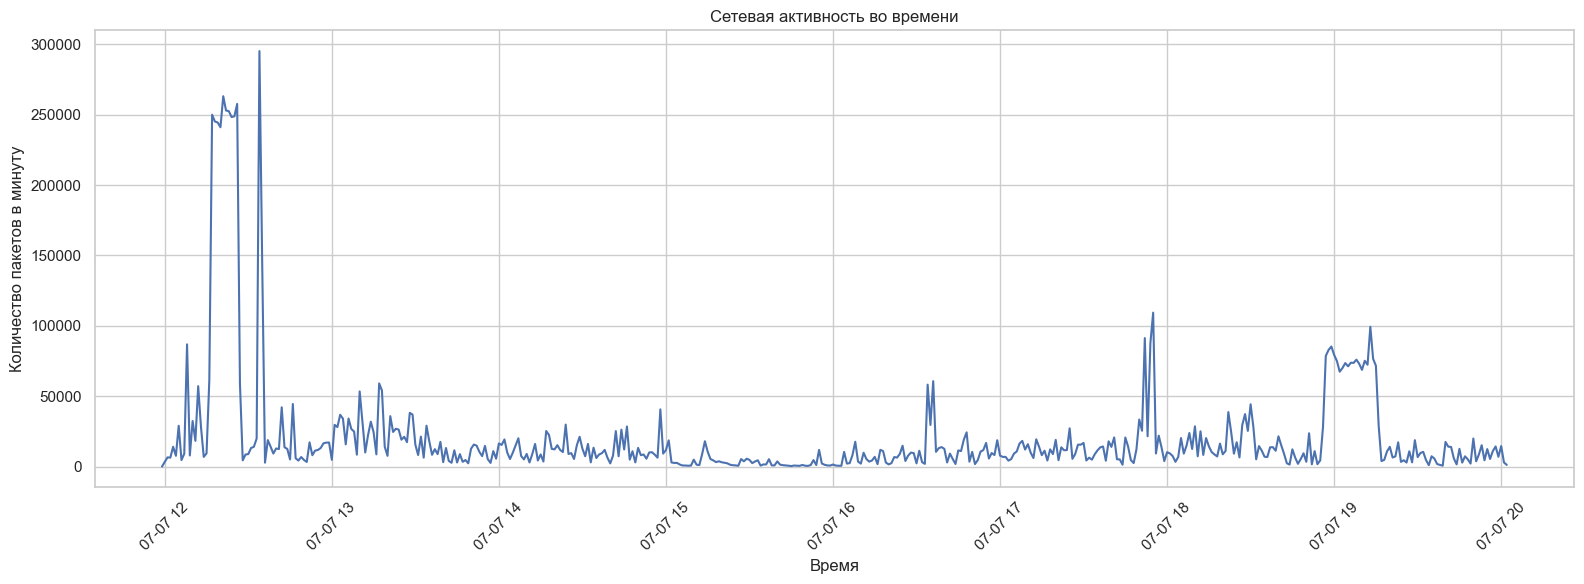

In [7]:
plt.figure(figsize=(16, 6))

plt.plot(
    df_minutes["datetime"],
    df_minutes["packets"]
)

plt.title("Сетевая активность во времени")
plt.xlabel("Время")
plt.ylabel("Количество пакетов в минуту")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

На графике видны несколько выраженных всплесков:
- В районе `12:20–12:35` — очень высокая активность, местами около 250 000 пакетов в минуту.
- Около `12:40` — отдельный пик почти до 300 000 пакетов.
- Около `17:50` — ещё один заметный всплеск.
- Около `19:00–19:15` — продолжительный период повышенной активности.

Наиболее интересные IP-адреса:

| IP-адрес | Пакетов-источников | Предварительная характеристика |
| :--- | ---: | :--- |
| 192.168.10.15 | 1 595 586 | Очень активный внутренний узел |
| 13.107.4.50 | 1 441 752 | Внешний узел |
| 172.16.0.1 | 927 429 | Внутренний узел |
| 192.168.10.50 | 778 932 | Внутренний узел |
| 192.168.10.3 | 368 389 | Внутренний узел |
| 8.253.104.126 | 234 365 | Внешний узел |
| 192.99.204.26 | 72 693 | Внешний узел |


Особенно интересны три направления:
1. `13.107.4.50 - 192.168.10.15` — более 2,49 млн пакетов в обе стороны.
2. `172.16.0.1 - 192.168.10.50` — более 1,6 млн пакетов.
3. `8.253.104.126 - 192.168.10.15` — более 415 тыс. пакетов.

Выделяются следующие порты:
- TCP 80 — HTTP.
- TCP 443 — HTTPS.
- UDP 53 — DNS.
- TCP 22 — SSH.
- TCP 389 и 3268 — LDAP и Global Catalog.
- TCP 21 — FTP.
- UDP 137 — NetBIOS Name Service.
- UDP 123 — NTP.
TCP 49808, 50273, 53564 и другие высокие порты могут быть динамическими клиентскими портами. Поэтому пока нельзя считать их подозрительными сервисами.

Выполним `классификацию` IP-адресов:

In [8]:
OUTPUT_DIR = Path(r"D:\Education\Лабы\Анализ данных\Friday_analysis_results")

# Загружаем статистику с диска
df_src = pd.read_csv(OUTPUT_DIR / "source_ips.csv")
df_dst = pd.read_csv(OUTPUT_DIR / "destination_ips.csv")

# Объединяем отправленные и полученные пакеты по каждому IP
df_ip_roles = pd.merge(
    df_src.rename(columns={"src_ip": "IP", "packets": "Отправлено"}),
    df_dst.rename(columns={"dst_ip": "IP", "packets": "Получено"}),
    on="IP",
    how="outer"
).fillna(0)

df_ip_roles["Отправлено"] = df_ip_roles["Отправлено"].astype(int)
df_ip_roles["Получено"] = df_ip_roles["Получено"].astype(int)
df_ip_roles["Всего пакетов"] = df_ip_roles["Отправлено"] + df_ip_roles["Получено"]

# Функция классификации
def classify_ip(ip):
    if ip in ("255.255.255.255", "192.168.10.255"):
        return "Broadcast"
    addr = ip_address(ip)
    if addr.is_multicast:
        return "Multicast"
    elif addr.is_loopback:
        return "Loopback"
    elif addr.is_link_local:
        return "Link-local"
    elif addr.is_unspecified:
        return "Unspecified (::)"
    elif addr.is_reserved:
        return "Reserved"
    elif addr.is_private:
        return "Внутренний (частный)"
    elif addr.is_global:
        return "Внешний (публичный)"
    return "Другой / специальный"

df_ip_roles["Категория"] = df_ip_roles["IP"].apply(classify_ip)
df_ip_roles = df_ip_roles.sort_values("Всего пакетов", ascending=False).reset_index(drop=True)

print("Распределение IP-адресов по категориям:")
display(df_ip_roles["Категория"].value_counts().to_frame("Количество"))

Распределение IP-адресов по категориям:


,Количество
Категория,
Внешний (публичный),8306
Multicast,17
Внутренний (частный),16
Link-local,11
Broadcast,2
Unspecified (::),1


Обнаружено 8 353 уникальных IP-адреса.

Выведем статистику наиболее часто встречающихся IP-адресов в каждой категории:

In [11]:
print("Топ-20 наиболее активных IP-адресов (по всем категориям):")
display(df_ip_roles.head(20))

print("Все внутренние (частные) хосты:")
df_internal = df_ip_roles[df_ip_roles["Категория"] == "Внутренний (частный)"]
display(df_internal)

print("Топ-20 внешних (публичных) IP-адресов:")
df_external = df_ip_roles[df_ip_roles["Категория"] == "Внешний (публичный)"]
display(df_external.head(20))

print("Служебные, широковещательные и групповые адреса:")
df_special = df_ip_roles[~df_ip_roles["Категория"].isin(["Внутренний (частный)", "Внешний (публичный)"])]
display(df_special)

Топ-20 наиболее активных IP-адресов (по всем категориям):


,IP,Отправлено,Получено,Всего пакетов,Категория
0,192.168.10.15,1595586,2056565,3652151,Внутренний (частный)
1,13.107.4.50,1441752,1062787,2504539,Внешний (публичный)
2,192.168.10.50,778932,1017478,1796410,Внутренний (частный)
3,172.16.0.1,927429,677829,1605258,Внутренний (частный)
4,192.168.10.3,368389,399202,767591,Внутренний (частный)
5,192.168.10.5,286964,306970,593934,Внутренний (частный)
6,192.168.10.14,274909,301001,575910,Внутренний (частный)
7,192.168.10.9,250597,287290,537887,Внутренний (частный)
8,192.168.10.16,232277,260624,492901,Внутренний (частный)
9,192.168.10.12,238288,254009,492297,Внутренний (частный)


Все внутренние (частные) хосты:


,IP,Отправлено,Получено,Всего пакетов,Категория
0,192.168.10.15,1595586,2056565,3652151,Внутренний (частный)
2,192.168.10.50,778932,1017478,1796410,Внутренний (частный)
3,172.16.0.1,927429,677829,1605258,Внутренний (частный)
4,192.168.10.3,368389,399202,767591,Внутренний (частный)
5,192.168.10.5,286964,306970,593934,Внутренний (частный)
6,192.168.10.14,274909,301001,575910,Внутренний (частный)
7,192.168.10.9,250597,287290,537887,Внутренний (частный)
8,192.168.10.16,232277,260624,492901,Внутренний (частный)
9,192.168.10.12,238288,254009,492297,Внутренний (частный)
10,192.168.10.8,211363,246375,457738,Внутренний (частный)


Топ-20 внешних (публичных) IP-адресов:


,IP,Отправлено,Получено,Всего пакетов,Категория
1,13.107.4.50,1441752,1062787,2504539,Внешний (публичный)
14,8.253.104.126,234365,181389,415754,Внешний (публичный)
15,192.99.204.26,72693,56336,129029,Внешний (публичный)
17,162.125.4.6,41393,33759,75152,Внешний (публичный)
18,91.189.88.162,30959,20334,51293,Внешний (публичный)
19,23.15.4.9,23242,25457,48699,Внешний (публичный)
20,199.244.48.55,25504,19841,45345,Внешний (публичный)
21,72.21.91.29,19680,24334,44014,Внешний (публичный)
22,91.189.88.161,23504,16271,39775,Внешний (публичный)
23,172.217.12.206,18228,13691,31919,Внешний (публичный)


Служебные, широковещательные и групповые адреса:


,IP,Отправлено,Получено,Всего пакетов,Категория
26,192.168.10.255,0,24928,24928,Broadcast
34,ff02::1:2,0,20440,20440,Multicast
108,fe80::3c60:fc97:3f94:ac8f,7273,0,7273,Link-local
111,fe80::f470:cd16:3cf6:bd7b,7241,0,7241,Link-local
125,fe80::6d07:ea13:6f73:ed41,6592,0,6592,Link-local
187,224.0.0.251,0,4505,4505,Multicast
255,ff02::fb,0,3390,3390,Multicast
455,224.0.0.252,0,1969,1969,Multicast
456,ff02::1,0,1968,1968,Multicast
524,ff02::1:3,0,1719,1719,Multicast


- Наиболее активный внутренний узел — `192.168.10.15`: более 3,65 млн пакетов в обе стороны.
- Второй по активности узел — `192.168.10.50`: около 1,8 млн пакетов.
- 192.168.10.3 также заслуживает внимания: он обменивается большим количеством UDP-пакетов с другими внутренними узлами.
Особенно интересны `192.168.10.15`, `192.168.10.50` и `192.168.10.3`. Пока это кандидаты для дальнейшего исследования, а не установленные источники атак.

* **Приоритет 1 — `192.168.10.15`** *(3 652 151 пакет)*. Самый активный внутренний узел. Взаимодействует с несколькими внешними адресами, в частности с `13.107.4.50` и `8.253.104.126`. Необходимо проверить характер этих соединений.

* **Приоритет 2 — `192.168.10.50`** *(1 796 410 пакетов)*. Основной партнёр по обмену трафиком — `172.16.0.1`. Нужно выяснить, какую роль выполняет этот узел и почему между ними такой большой объём трафика.

* **Приоритет 3 — `172.16.0.1`** *(1 605 258 пакетов)*. Интенсивно обменивается данными с `192.168.10.50`. Возможно, это сетевой шлюз или другой инфраструктурный узел, но пока это только гипотеза.

* **Приоритет 4 — `192.168.10.3`** *(767 591 пакет)*. Обменивается большим количеством UDP-пакетов с другими внутренними узлами. Стоит проверить, какие именно UDP-протоколы используются.

* **Приоритет 5 — `192.168.10.25`** *(454 799 пакетов)*. Установлено интенсивное TCP-взаимодействие с `192.99.204.26`. Это направление необходимо исследовать отдельно.


**Анализ multicast-адресов**


| Адрес | Назначение |
| :--- | :--- |
| 224.0.0.251 | mDNS — обнаружение устройств и служб в локальной сети |
| ff02::fb | mDNS для IPv6 |
| 224.0.0.252 | LLMNR — разрешение имён в локальной сети |
| 239.255.255.250 | SSDP — обнаружение сетевых устройств |
| ff02::1 | Все узлы локального IPv6-сегмента |
| ff02::2 | IPv6-маршрутизаторы |
| ff02::1:2 | DHCPv6-серверы и ретрансляторы |


Большая часть этих адресов связана с обычными сетевыми механизмами обнаружения устройств и разрешения имён. Однако mDNS и LLMNR в дальнейшем стоит учитывать при исследовании возможных атак на разрешение имён.

**Выполним поиск признаков TCP-сканирования**

Реализуем потоковый проход по PCAP-дампу с отбором только пакетов **инициации TCP-соединений (`SYN=1, ACK=0`)**. Это позволяет выявить аномальную активность до завершения рукопожатия. Результаты аналогично сохраним в CSV-файл.

In [12]:
# Папка для результатов
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Проверка: является ли адрес внутренним unicast-адресом
def is_internal_unicast(ip):
    addr = ip_address(ip)
    if (addr.is_multicast or addr.is_loopback or
        addr.is_link_local or addr.is_unspecified):
        return False
    return addr.is_private

# Общая статистика по источникам
syn_by_src = defaultdict(lambda: {
    "packets": 0,
    "dst_ips": set(),
    "dst_ports": set(),
    "first_seen": None,
    "last_seen": None
})

# Статистика по парам источник -> получатель
syn_by_pair = defaultdict(lambda: {
    "packets": 0,
    "dst_ports": set(),
    "first_seen": None,
    "last_seen": None
})

# Активность источников по минутам
syn_by_minute = defaultdict(lambda: {
    "packets": 0,
    "dst_ips": set(),
    "dst_ports": set()
})

total_syn = 0
with PcapReader(str(PCAP_PATH)) as reader:
    for pkt in tqdm(reader, desc="Анализ TCP SYN", unit="пакетов"):
        if not pkt.haslayer(TCP):
            continue
        tcp = pkt[TCP]
        flags = int(tcp.flags)
        # SYN = 1, ACK = 0
        if not (flags & 0x02) or (flags & 0x10):
            continue
        # Получаем IP-адреса
        if pkt.haslayer(IP):
            src = pkt[IP].src
            dst = pkt[IP].dst
        elif pkt.haslayer(IPv6):
            src = pkt[IPv6].src
            dst = pkt[IPv6].dst
        else:
            continue
        sport = int(tcp.sport)
        dport = int(tcp.dport)
        timestamp = float(pkt.time)
        minute = datetime.fromtimestamp(
            timestamp, timezone.utc
        ).strftime("%Y-%m-%d %H:%M")
        total_syn += 1
        # Статистика по источнику
        s = syn_by_src[src]
        s["packets"] += 1
        s["dst_ips"].add(dst)
        s["dst_ports"].add(dport)
        if s["first_seen"] is None or timestamp < s["first_seen"]:
            s["first_seen"] = timestamp
        if s["last_seen"] is None or timestamp > s["last_seen"]:
            s["last_seen"] = timestamp
        # Статистика по паре IP
        p = syn_by_pair[(src, dst)]
        p["packets"] += 1
        p["dst_ports"].add(dport)
        if p["first_seen"] is None or timestamp < p["first_seen"]:
            p["first_seen"] = timestamp
        if p["last_seen"] is None or timestamp > p["last_seen"]:
            p["last_seen"] = timestamp
        # Статистика по минутам
        m = syn_by_minute[(src, minute)]
        m["packets"] += 1
        m["dst_ips"].add(dst)
        m["dst_ports"].add(dport)

print("\nАнализ завершён.")
print(f"Всего TCP SYN-пакетов: {total_syn:,}")
print(f"Уникальных источников SYN: {len(syn_by_src):,}")
print(f"Уникальных пар источник-получатель: {len(syn_by_pair):,}")

# 1. Сводная статистика по источникам
source_rows = []
for src, data in syn_by_src.items():
    source_rows.append({
        "Источник": src,
        "Внутренний": is_internal_unicast(src),
        "SYN-пакетов": data["packets"],
        "Уникальных IP назначения": len(data["dst_ips"]),
        "Уникальных портов назначения": len(data["dst_ports"]),
        "Первый SYN (UTC)": datetime.fromtimestamp(
            data["first_seen"], timezone.utc
        ).isoformat(),
        "Последний SYN (UTC)": datetime.fromtimestamp(
            data["last_seen"], timezone.utc
        ).isoformat()
    })
df_syn_sources = pd.DataFrame(source_rows)
df_syn_sources = df_syn_sources.sort_values(
    "Уникальных портов назначения",
    ascending=False
)

# 2. Статистика по парам IP
pair_rows = []
for (src, dst), data in syn_by_pair.items():
    pair_rows.append({
        "Источник": src,
        "Получатель": dst,
        "SYN-пакетов": data["packets"],
        "Уникальных портов назначения": len(data["dst_ports"]),
        "Порты назначения": ",".join(
            map(str, sorted(data["dst_ports"])[:50])
        ),
        "Первый SYN (UTC)": datetime.fromtimestamp(
            data["first_seen"], timezone.utc
        ).isoformat(),
        "Последний SYN (UTC)": datetime.fromtimestamp(
            data["last_seen"], timezone.utc
        ).isoformat()
    })
df_syn_pairs = pd.DataFrame(pair_rows)
df_syn_pairs = df_syn_pairs.sort_values(
    ["Уникальных портов назначения", "SYN-пакетов"],
    ascending=False
)

# 3. Статистика по минутам
minute_rows = []
for (src, minute), data in syn_by_minute.items():
    minute_rows.append({
        "Источник": src,
        "Минута (UTC)": minute,
        "SYN-пакетов": data["packets"],
        "Уникальных IP назначения": len(data["dst_ips"]),
        "Уникальных портов назначения": len(data["dst_ports"])
    })
df_syn_minutes = pd.DataFrame(minute_rows)
df_syn_minutes = df_syn_minutes.sort_values(
    "SYN-пакетов",
    ascending=False
)

# 4. Отдельно выделяем внутренние источники
df_internal_syn = df_syn_sources[
    df_syn_sources["Внутренний"] == True
].copy()
df_internal_syn = df_internal_syn.sort_values(
    ["Уникальных портов назначения",
     "Уникальных IP назначения",
     "SYN-пакетов"],
    ascending=False
)

# 5. Сохранение результатов
df_syn_sources.to_csv(
    OUTPUT_DIR / "tcp_syn_sources.csv",
    index=False,
    encoding="utf-8-sig"
)

df_syn_pairs.to_csv(
    OUTPUT_DIR / "tcp_syn_pairs.csv",
    index=False,
    encoding="utf-8-sig"
)

df_syn_minutes.to_csv(
    OUTPUT_DIR / "tcp_syn_minutes.csv",
    index=False,
    encoding="utf-8-sig"
)

df_internal_syn.to_csv(
    OUTPUT_DIR / "tcp_syn_internal_sources.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nРезультаты сохранены в:", OUTPUT_DIR)

# Выведем статистику
print("\nТоп-30 источников по количеству уникальных портов:")
display(df_syn_sources.head(30))
print("\nВнутренние источники SYN:")
display(df_internal_syn)
print("\nТоп-30 пар по количеству уникальных портов:")
display(df_syn_pairs.head(30))
print("\nТоп-30 минут с наибольшим количеством SYN:")
display(df_syn_minutes.head(30))

Анализ TCP SYN: 9997874пакетов [21:07, 7890.29пакетов/s]



Анализ завершён.
Всего TCP SYN-пакетов: 352,955
Уникальных источников SYN: 14
Уникальных пар источник-получатель: 17,554

Результаты сохранены в: D:\Education\Лабы\Анализ данных\Friday_analysis_results

Топ-30 источников по количеству уникальных портов:


,Источник,Внутренний,SYN-пакетов,Уникальных IP назначения,Уникальных портов назначения,Первый SYN (UTC),Последний SYN (UTC)
13,172.16.0.1,True,255796,1,999,2017-07-07T14:47:47.186107+00:00,2017-07-07T19:16:10.645771+00:00
2,192.168.10.5,True,12712,2071,71,2017-07-07T12:00:50.222855+00:00,2017-07-07T20:01:40.119839+00:00
8,192.168.10.12,True,9888,1792,65,2017-07-07T12:07:32.268248+00:00,2017-07-07T20:02:10.023084+00:00
1,192.168.10.14,True,10548,1958,64,2017-07-07T12:00:48.891565+00:00,2017-07-07T20:02:04.562636+00:00
7,192.168.10.16,True,8653,1659,63,2017-07-07T12:07:17.287484+00:00,2017-07-07T20:00:46.192033+00:00
4,192.168.10.8,True,9447,1625,60,2017-07-07T12:01:10.655183+00:00,2017-07-07T20:02:38.575270+00:00
0,192.168.10.9,True,10609,1948,57,2017-07-07T12:00:35.337052+00:00,2017-07-07T20:01:08.158361+00:00
9,192.168.10.15,True,13202,2269,57,2017-07-07T12:08:11.648678+00:00,2017-07-07T20:01:21.730729+00:00
3,192.168.10.25,True,5717,1017,54,2017-07-07T12:01:05.941292+00:00,2017-07-07T20:01:22.085453+00:00
6,192.168.10.17,True,7203,1513,51,2017-07-07T12:01:45.218812+00:00,2017-07-07T20:02:39.567289+00:00



Внутренние источники SYN:


,Источник,Внутренний,SYN-пакетов,Уникальных IP назначения,Уникальных портов назначения,Первый SYN (UTC),Последний SYN (UTC)
13,172.16.0.1,True,255796,1,999,2017-07-07T14:47:47.186107+00:00,2017-07-07T19:16:10.645771+00:00
2,192.168.10.5,True,12712,2071,71,2017-07-07T12:00:50.222855+00:00,2017-07-07T20:01:40.119839+00:00
8,192.168.10.12,True,9888,1792,65,2017-07-07T12:07:32.268248+00:00,2017-07-07T20:02:10.023084+00:00
1,192.168.10.14,True,10548,1958,64,2017-07-07T12:00:48.891565+00:00,2017-07-07T20:02:04.562636+00:00
7,192.168.10.16,True,8653,1659,63,2017-07-07T12:07:17.287484+00:00,2017-07-07T20:00:46.192033+00:00
4,192.168.10.8,True,9447,1625,60,2017-07-07T12:01:10.655183+00:00,2017-07-07T20:02:38.575270+00:00
9,192.168.10.15,True,13202,2269,57,2017-07-07T12:08:11.648678+00:00,2017-07-07T20:01:21.730729+00:00
0,192.168.10.9,True,10609,1948,57,2017-07-07T12:00:35.337052+00:00,2017-07-07T20:01:08.158361+00:00
3,192.168.10.25,True,5717,1017,54,2017-07-07T12:01:05.941292+00:00,2017-07-07T20:01:22.085453+00:00
6,192.168.10.17,True,7203,1513,51,2017-07-07T12:01:45.218812+00:00,2017-07-07T20:02:39.567289+00:00



Топ-30 пар по количеству уникальных портов:


,Источник,Получатель,SYN-пакетов,Уникальных портов назначения,Порты назначения,Первый SYN (UTC),Последний SYN (UTC)
9051,172.16.0.1,192.168.10.50,255796,999,"1,3,4,6,7,9,13,17,19,20,21,22,23,24,25,26,30,3...",2017-07-07T14:47:47.186107+00:00,2017-07-07T19:16:10.645771+00:00
119,192.168.10.5,192.168.10.50,448,59,"21,22,6131,6322,6373,7219,9621,9984,10158,1127...",2017-07-07T12:05:14.913185+00:00,2017-07-07T20:01:40.119839+00:00
522,192.168.10.12,192.168.10.50,434,58,"21,22,139,5475,9425,9992,10222,14417,15751,158...",2017-07-07T12:10:54.439710+00:00,2017-07-07T19:55:39.441993+00:00
427,192.168.10.16,192.168.10.50,458,55,"21,22,139,6724,8393,10014,10774,12631,12714,16...",2017-07-07T12:09:07.528310+00:00,2017-07-07T20:00:46.192033+00:00
63,192.168.10.14,192.168.10.50,424,53,"21,22,6830,7350,8327,9670,10875,12837,14409,16...",2017-07-07T12:03:47.617936+00:00,2017-07-07T19:29:25.610397+00:00
13,192.168.10.25,192.168.10.50,524,50,"21,80,139,5943,6024,6328,6756,7500,9477,13146,...",2017-07-07T12:01:24.120108+00:00,2017-07-07T20:01:22.085453+00:00
346,192.168.10.8,192.168.10.50,380,49,"21,22,6970,7951,9621,15722,15833,16780,17940,1...",2017-07-07T12:06:12.701697+00:00,2017-07-07T20:00:33.266776+00:00
20,192.168.10.9,192.168.10.50,404,47,"21,22,5389,7511,10602,13614,14055,14194,18498,...",2017-07-07T12:02:25.145992+00:00,2017-07-07T19:25:07.134916+00:00
705,192.168.10.51,185.170.48.239,45,45,"21,5994,6726,8774,9465,11271,13999,15538,15802...",2017-07-07T12:12:18.711501+00:00,2017-07-07T12:12:46.229042+00:00
464,192.168.10.15,192.168.10.50,404,44,"21,22,6526,11164,12469,14167,16209,16665,17423...",2017-07-07T12:10:06.781152+00:00,2017-07-07T19:57:50.730489+00:00



Топ-30 минут с наибольшим количеством SYN:


,Источник,Минута (UTC),SYN-пакетов,Уникальных IP назначения,Уникальных портов назначения
2890,172.16.0.1,2017-07-07 17:55,44865,1,997
2858,172.16.0.1,2017-07-07 17:52,43868,1,997
2884,172.16.0.1,2017-07-07 17:54,34896,1,998
2851,172.16.0.1,2017-07-07 17:51,10971,1,997
3563,172.16.0.1,2017-07-07 19:06,5085,1,1
3155,172.16.0.1,2017-07-07 18:22,5040,1,999
3020,172.16.0.1,2017-07-07 18:08,5040,1,999
3518,172.16.0.1,2017-07-07 19:01,4970,1,1
3619,172.16.0.1,2017-07-07 19:12,4947,1,1
3601,172.16.0.1,2017-07-07 19:10,4939,1,1


Полученные результаты уже выявили очень сильный кандидат на **TCP-сканирование**. Самое важное наблюдение — активность `172.16.0.1` в отношении `192.168.10.50`.

**Ключевой инцидент:** `172.16.0.1` -> `192.168.10.50`
* **SYN-пакетов:** 255 796
* **Уникальных портов назначения:** 999
* **Период активности:** с `14:47:47` до `19:16:10` UTC

Один адрес назначения — `192.168.10.50`. Это характерный признак возможного `вертикального сканирования портов`: один источник проверяет большое количество портов одного узла.

**Временные всплески активности**
Особенно показательны пиковые нагрузки (в эти минуты проверялось примерно 997–998 различных портов, что существенно усиливает гипотезу сканирования):

| Время UTC | SYN-пакетов за минуту |
| :---: | ---: |
| 17:51 | 10 971 |
| 17:52 | 43 868 |
| 17:53 | 3 988 |
| 17:54 | 34 896 |
| 17:55 | 44 865 |

**Примечание:** Пока не будем окончательно называть это подтверждённой атакой. Важно проверить, отвечал ли `192.168.10.50` на запросы, какие порты были доступны и сколько попыток завершилось сбросом соединения или отсутствием ответа.

**Дополнительные аномалии**
* **Внешний кандидат на сканирование:** `192.168.10.51` - `185.170.48.239` — зафиксировано 45 SYN-пакетов к 45 различным портам всего за 28 секунд.
* **Внутренняя активность:** несколько рабочих станций обращаются к `192.168.10.50` по десяткам различных портов. Это может быть как штатное обнаружение служб, так и дополнительная разведка.

**Проверка ответов на SYN**

Проведём ещё один проход по PCAP-дампу, ограничив анализ интересующими нас парами адресов. Для каждого порта подсчитаем соотношение запросов и ответов по следующим флагам:

* **`SYN`** — попытки инициировать соединение.
* **`SYN-ACK`** — ответ, указывающий на открытый порт или готовность принять соединение.
* **`RST`** — принудительный сброс соединения (закрытый порт).
* **Нет ответа** — отсутствие `SYN-ACK` и `RST` в обратном направлении в захваченном трафике.

Анализ соотношения этих флагов позволит точно отличить нелегитимное сканирование от обычного сетевого обмена.


In [14]:
candidate_pairs = {
    ("172.16.0.1", "192.168.10.50"),
    ("192.168.10.5", "192.168.10.50"),
    ("192.168.10.12", "192.168.10.50"),
    ("192.168.10.14", "192.168.10.50"),
    ("192.168.10.16", "192.168.10.50"),
    ("192.168.10.8", "192.168.10.50"),
    ("192.168.10.9", "192.168.10.50"),
    ("192.168.10.15", "192.168.10.50"),
    ("192.168.10.25", "192.168.10.50"),
    ("192.168.10.17", "192.168.10.50"),
    ("192.168.10.19", "192.168.10.50"),
    ("192.168.10.51", "185.170.48.239")
}

# Учитываем прямое и обратное направления обмена
allowed_pairs = candidate_pairs | {(dst, src) for src, dst in candidate_pairs}
flow_stats = defaultdict(lambda: {
    "SYN": 0,
    "SYN_ACK": 0,
    "RST": 0,
    "OTHER": 0,
    "first_syn": None,
    "last_syn": None
})

start_time = time.time()
with PcapReader(str(PCAP_PATH)) as reader:
    for pkt in tqdm(reader, desc="Проверка TCP-ответов", unit="пакетов"):
        if IP not in pkt or TCP not in pkt:
            continue
        src, dst = pkt[IP].src, pkt[IP].dst
        if (src, dst) not in allowed_pairs:
            continue
        tcp = pkt[TCP]
        sport, dport = int(tcp.sport), int(tcp.dport)
        flags = int(tcp.flags)
        timestamp = float(pkt.time)
        stat = flow_stats[(src, sport, dst, dport)]
        if (flags & 0x02) and not (flags & 0x10): # SYN без ACK
            stat["SYN"] += 1
            if stat["first_syn"] is None:
                stat["first_syn"] = timestamp
            stat["last_syn"] = timestamp
        elif (flags & 0x12) == 0x12:  # SYN + ACK
            stat["SYN_ACK"] += 1
        elif flags & 0x04: # RST
            stat["RST"] += 1
        else:
            stat["OTHER"] += 1

rows = []
for src, dst in candidate_pairs:
    for (flow_src, sport, flow_dst, dport), stat in flow_stats.items():
        if flow_src != src or flow_dst != dst or stat["SYN"] == 0:
            continue
        reverse_stat = flow_stats.get((dst, dport, src, sport), {})
        rows.append({
            "Источник": src,
            "Получатель": dst,
            "Порт назначения": dport,
            "SYN": stat["SYN"],
            "SYN-ACK": reverse_stat.get("SYN_ACK", 0),
            "RST": reverse_stat.get("RST", 0),
            "Другие ответные пакеты": reverse_stat.get("OTHER", 0),
            "Исходный порт": sport,
            "Первый SYN (UTC)": pd.to_datetime(stat["first_syn"], unit="s", utc=True),
            "Последний SYN (UTC)": pd.to_datetime(stat["last_syn"], unit="s", utc=True)
        })

df_syn_responses = (
    pd.DataFrame(rows)
    .groupby(["Источник", "Получатель", "Порт назначения"], as_index=False)
    .agg({
        "SYN": "sum",
        "SYN-ACK": "sum",
        "RST": "sum",
        "Другие ответные пакеты": "sum",
        "Исходный порт": "nunique",
        "Первый SYN (UTC)": "min",
        "Последний SYN (UTC)": "max"
    })
    .rename(columns={"Исходный порт": "Уникальных исходных портов"})
)

df_syn_responses["Доля SYN-ACK, %"] = (df_syn_responses["SYN-ACK"] / df_syn_responses["SYN"] * 100).fillna(0).round(2)
df_syn_responses["Доля RST, %"] = (df_syn_responses["RST"] / df_syn_responses["SYN"] * 100).fillna(0).round(2)

output_file = OUTPUT_DIR / "tcp_syn_response_analysis.csv"
df_syn_responses.to_csv(output_file, index=False, encoding="utf-8-sig")

print(f"Сохранено в: {output_file}")
display(df_syn_responses.sort_values("SYN", ascending=False).head(20))

Проверка TCP-ответов: 9997874пакетов [20:23, 8168.73пакетов/s]


Сохранено в: D:\Education\Лабы\Анализ данных\Friday_analysis_results\tcp_syn_response_analysis.csv


,Источник,Получатель,Порт назначения,SYN,SYN-ACK,RST,Другие ответные пакеты,Уникальных исходных портов,Первый SYN (UTC),Последний SYN (UTC),"Доля SYN-ACK, %","Доля RST, %"
26,172.16.0.1,192.168.10.50,80,96003,96006,0,421542,45525,2017-07-07 14:47:47.186106920+00:00,2017-07-07 19:16:10.645771027+00:00,100.0,0.0
1295,192.168.10.25,192.168.10.50,139,322,322,0,4832,161,2017-07-07 12:01:24.120107889+00:00,2017-07-07 20:01:22.085453033+00:00,100.0,0.0
1155,192.168.10.16,192.168.10.50,22,248,248,0,5244,124,2017-07-07 12:09:08.963851929+00:00,2017-07-07 20:00:46.192033052+00:00,100.0,0.0
10,172.16.0.1,192.168.10.50,21,244,244,0,65,243,2017-07-07 16:55:32.120153904+00:00,2017-07-07 18:23:53.253667116+00:00,100.0,0.0
11,172.16.0.1,192.168.10.50,22,243,243,0,70,242,2017-07-07 16:55:32.120157003+00:00,2017-07-07 18:23:53.253716946+00:00,100.0,0.0
73,172.16.0.1,192.168.10.50,443,241,0,241,0,241,2017-07-07 16:55:32.117089987+00:00,2017-07-07 18:23:51.938339949+00:00,0.0,100.0
1111,192.168.10.15,192.168.10.50,22,236,236,0,5244,118,2017-07-07 12:10:31.010195971+00:00,2017-07-07 19:26:27.072931051+00:00,100.0,0.0
1497,192.168.10.9,192.168.10.50,22,224,224,0,4572,112,2017-07-07 12:02:28.196197987+00:00,2017-07-07 18:59:16.081641912+00:00,100.0,0.0
1058,192.168.10.14,192.168.10.50,22,220,220,0,4874,110,2017-07-07 12:04:01.345082045+00:00,2017-07-07 19:28:26.771323919+00:00,100.0,0.0
1344,192.168.10.5,192.168.10.50,22,220,220,0,4458,110,2017-07-07 12:05:22.437886953+00:00,2017-07-07 20:01:40.119838953+00:00,100.0,0.0


Выведем статистику ответов на SYN:

In [18]:
df_syn_responses = pd.read_csv(OUTPUT_DIR / "tcp_syn_response_analysis.csv")

# Сводная таблица по каждому направлению
syn_summary = (
    df_syn_responses
    .groupby(["Источник", "Получатель"], as_index=False)
    .agg({
        "Порт назначения": "nunique",
        "SYN": "sum",
        "SYN-ACK": "sum",
        "RST": "sum",
        "Другие ответные пакеты": "sum",
        "Уникальных исходных портов": "sum",
        "Первый SYN (UTC)": "min",
        "Последний SYN (UTC)": "max"
    })
    .rename(columns={"Порт назначения": "Проверено портов"})
)

syn_summary["Доля SYN-ACK, %"] = (syn_summary["SYN-ACK"] / syn_summary["SYN"] * 100).round(2)
syn_summary["Доля RST, %"] = (syn_summary["RST"] / syn_summary["SYN"] * 100).round(2)
syn_summary["Без ответа, %"] = (100 - syn_summary["Доля SYN-ACK, %"] - syn_summary["Доля RST, %"]).clip(lower=0).round(2)

print("Таблица ответов на SYN по кандидатам:")
display(syn_summary.sort_values("SYN", ascending=False))

print("\nДетализация по 172.16.0.1 -> 192.168.10.50 (открытые и закрытые порты):")
scan_main = df_syn_responses[(df_syn_responses["Источник"] == "172.16.0.1") & (df_syn_responses["Получатель"] == "192.168.10.50")]
display(scan_main.sort_values("SYN", ascending=False).head(15))

Таблица ответов на SYN по кандидатам:


,Источник,Получатель,Проверено портов,SYN,SYN-ACK,RST,Другие ответные пакеты,Уникальных исходных портов,Первый SYN (UTC),Последний SYN (UTC),"Доля SYN-ACK, %","Доля RST, %","Без ответа, %"
0,172.16.0.1,192.168.10.50,999,255796,96871,158798,421830,204884,2017-07-07 14:47:47.186106920+00:00,2017-07-07 19:16:10.645771027+00:00,37.87,62.08,0.05
7,192.168.10.25,192.168.10.50,50,524,524,0,7150,262,2017-07-07 12:01:24.120107889+00:00,2017-07-07 20:01:22.085453033+00:00,100.00,0.00,0.00
4,192.168.10.16,192.168.10.50,55,458,458,0,7156,229,2017-07-07 12:09:07.528310061+00:00,2017-07-07 20:00:46.192033052+00:00,100.00,0.00,0.00
8,192.168.10.5,192.168.10.50,59,448,448,0,6416,224,2017-07-07 12:05:14.913184881+00:00,2017-07-07 20:01:40.119838953+00:00,100.00,0.00,0.00
1,192.168.10.12,192.168.10.50,58,434,434,0,6538,217,2017-07-07 12:10:54.439709902+00:00,2017-07-07 19:55:39.441992998+00:00,100.00,0.00,0.00
2,192.168.10.14,192.168.10.50,53,424,424,0,6630,212,2017-07-07 12:03:47.617935896+00:00,2017-07-07 19:29:25.610397100+00:00,100.00,0.00,0.00
3,192.168.10.15,192.168.10.50,44,404,404,0,6674,202,2017-07-07 12:10:06.781152010+00:00,2017-07-07 19:57:50.730489016+00:00,100.00,0.00,0.00
11,192.168.10.9,192.168.10.50,47,404,404,0,6098,202,2017-07-07 12:02:25.145992041+00:00,2017-07-07 19:25:07.134916067+00:00,100.00,0.00,0.00
10,192.168.10.8,192.168.10.50,49,380,380,0,5518,190,2017-07-07 12:06:12.701697111+00:00,2017-07-07 20:00:33.266776085+00:00,100.00,0.00,0.00
5,192.168.10.17,192.168.10.50,43,376,376,0,5876,188,2017-07-07 12:05:41.401141882+00:00,2017-07-07 20:02:39.567289114+00:00,100.00,0.00,0.00



Детализация по 172.16.0.1 -> 192.168.10.50 (открытые и закрытые порты):


,Источник,Получатель,Порт назначения,SYN,SYN-ACK,RST,Другие ответные пакеты,Уникальных исходных портов,Первый SYN (UTC),Последний SYN (UTC),"Доля SYN-ACK, %","Доля RST, %"
26,172.16.0.1,192.168.10.50,80,96003,96006,0,421542,45525,2017-07-07 14:47:47.186106920+00:00,2017-07-07 19:16:10.645771027+00:00,100.0,0.0
10,172.16.0.1,192.168.10.50,21,244,244,0,65,243,2017-07-07 16:55:32.120153904+00:00,2017-07-07 18:23:53.253667116+00:00,100.0,0.0
11,172.16.0.1,192.168.10.50,22,243,243,0,70,242,2017-07-07 16:55:32.120157003+00:00,2017-07-07 18:23:53.253716946+00:00,100.0,0.0
73,172.16.0.1,192.168.10.50,443,241,0,241,0,241,2017-07-07 16:55:32.117089987+00:00,2017-07-07 18:23:51.938339949+00:00,0.0,100.0
74,172.16.0.1,192.168.10.50,444,210,0,210,0,210,2017-07-07 16:55:36.334785938+00:00,2017-07-07 18:23:52.021532059+00:00,0.0,100.0
44,172.16.0.1,192.168.10.50,139,198,198,0,94,196,2017-07-07 17:51:45.450577974+00:00,2017-07-07 18:23:53.253706932+00:00,100.0,0.0
75,172.16.0.1,192.168.10.50,445,180,180,0,59,180,2017-07-07 17:51:45.454102993+00:00,2017-07-07 18:23:53.253755093+00:00,100.0,0.0
6,172.16.0.1,192.168.10.50,13,160,0,160,0,160,2017-07-07 17:51:45.509593010+00:00,2017-07-07 18:23:51.967597961+00:00,0.0,100.0
969,172.16.0.1,192.168.10.50,50636,160,0,160,0,160,2017-07-07 17:51:45.491672993+00:00,2017-07-07 18:23:51.955136061+00:00,0.0,100.0
22,172.16.0.1,192.168.10.50,49,160,0,160,0,160,2017-07-07 17:51:45.483062983+00:00,2017-07-07 18:23:51.954401970+00:00,0.0,100.0


**Выводы по анализу TCP-ответов**

1. **Подтверждено вертикальное сканирование портов (`172.16.0.1 -> 192.168.10.50`):**
   - Источник проверил 999 уникальных портов целевого хоста.
   - На 994 закрытых портах (например, 79, 70, 53, 443, 444 и др.) целевой узел ответил 100% RST (принудительный сброс соединения, по 160 сбросов на каждый закрытый порт).
   - Открытыми оказались только 5 портов, на которые сервер ответил 100% SYN-ACK: 21 (FTP), 22 (SSH), 80 (HTTP), 139 (NetBIOS) и 445 (SMB).
2. **Обнаружена массивная DoS/DDoS-атака на веб-сервер (`172.16.0.1 -> 192.168.10.50:80`):**
   - Поверх сканирования зафиксировано 96 003 SYN-запроса с 45 525 уникальных исходных портов исключительно на порт 80 (активная фаза около `18:56–19:16` UTC), что указывает на автоматизированную HTTP/SYN-нагрузку.
3. **Неподтверждённая аномалия (`192.168.10.51 -> 185.170.48.239`):**
   - За 28 секунд (`12:12:18–12:12:46` UTC) отправлено 45 SYN-пакетов на 45 уникальных портов внешнего IP без единого ответа.
4. **Легитимный обмен рабочих станций с `192.168.10.50`:**
   - Внутренние хосты (`192.168.10.5`, `.12`, `.15` и др.) получали 100% SYN-ACK и тысячи пакетов полезной нагрузки на порт `22` (SSH) и высокие динамические порты (штатный FTP Passive Mode). Узел - 192.168.10.3 - контроллер домена Active Directory.


**Анализ периодичности и контента прикладного уровня (HTTP / DNS)**

Чтобы выявить скрытые этапы атаки (управление ботнетом / Command & Control, эксфильтрацию данных и веб-атаки на уровне приложений), проведём целевой потоковый проход по дампу для извлечения:
- **Метрик биконинга:** вычисление среднего межинтервального времени (IAT) и коэффициента вариации (CV) между повторяющимися TCP-соединениями. Низкий CV указывает на автоматический периодический «стук» вредоносного ПО на управляющий сервер.
- **HTTP-трафика:** методы, URI, заголовки `Host`, `User-Agent` и коды ответов (поиск 4xx/5xx ошибок и инъекций).
- **DNS-трафика:** частота запросов и поиск `NXDOMAIN` / DGA-доменов.


In [19]:
RE_HTTP_REQ  = re.compile(rb"^(?P<method>GET|POST|PUT|DELETE|HEAD|OPTIONS|PATCH)\s+(?P<uri>\S+)\s+HTTP/1\.", re.M)
RE_HTTP_HDR  = re.compile(rb"^(?P<name>[A-Za-z\-]+):\s*(?P<val>[^\r\n]+)", re.M)
RE_HTTP_RESP = re.compile(rb"^HTTP/1\.\s+(?P<code>\d{3})", re.M)

http_events = []
dns_queries = Counter()
dns_nxdomain = Counter()
conn_times = defaultdict(list)
service_traffic = defaultdict(lambda: {"pkts": 0, "bytes": 0})

start_t = time.time()
with PcapReader(str(PCAP_PATH)) as reader:
    for pkt in tqdm(reader, desc="L7 и C2 анализ", unit="пакетов"):
        if IP not in pkt:
            continue
        src, dst = pkt[IP].src, pkt[IP].dst
        ts, plen = float(pkt.time), len(pkt)

        if TCP in pkt:
            tcp = pkt[TCP]
            sport, dport, flags = int(tcp.sport), int(tcp.dport), int(tcp.flags)

            # Запоминаем время новых соединений (SYN без ACK)
            if (flags & 0x02) and not (flags & 0x10):
                conn_times[(src, dst, dport)].append(ts)

            # Считаем объём байт по ключевым сервисам
            for p in (21, 22, 80, 443, 444, 445, 8080, 8443):
                if dport == p or sport == p:
                    service_traffic[(src, dst, p)]["pkts"] += 1
                    service_traffic[(src, dst, p)]["bytes"] += plen
                    break

            # Извлекаем HTTP-заголовки
            if Raw in pkt:
                raw = bytes(pkt[Raw].load)[:1200]
                if b"HTTP/1." in raw:
                    ev = {"ts": ts, "src_ip": src, "dst_ip": dst, "sport": sport, "dport": dport,
                          "method": None, "uri": None, "host": None, "ua": None, "code": None}
                    m = RE_HTTP_REQ.search(raw)
                    if m:
                        ev["method"] = m.group("method").decode(errors="ignore")
                        ev["uri"] = m.group("uri").decode(errors="ignore")
                    m = RE_HTTP_RESP.search(raw)
                    if m:
                        ev["code"] = int(m.group("code"))
                    for hm in RE_HTTP_HDR.finditer(raw):
                        k = hm.group("name").decode(errors="ignore").lower()
                        v = hm.group("val").decode(errors="ignore")
                        if k == "host": ev["host"] = v
                        elif k == "user-agent": ev["ua"] = v
                    http_events.append(ev)

        elif UDP in pkt and DNS in pkt:
            dns = pkt[DNS]
            try:
                if dns.qd is not None:
                    qname = dns.qd.qname.decode(errors="ignore").rstrip(".")
                    if int(dns.qr) == 0:
                        dns_queries[(src, qname)] += 1
                    elif int(dns.rcode) == 3:
                        dns_nxdomain[(dst, qname)] += 1
            except Exception:
                pass

# Сохраняем HTTP
df_http = pd.DataFrame(http_events)
if not df_http.empty:
    df_http["dt"] = pd.to_datetime(df_http["ts"], unit="s", utc=True)
    df_http.to_csv(OUTPUT_DIR / "http_events.csv", index=False, encoding="utf-8-sig")

# Сохраняем DNS
df_dns = pd.DataFrame([{"src_ip": k, "qname": k, "count": v} for k, v in dns_queries.items()])
df_dns.to_csv(OUTPUT_DIR / "dns_queries.csv", index=False, encoding="utf-8-sig")

# Расчет биконинга (периодичности соединений)
beacon_rows = []
for (src, dst, dport), times in conn_times.items():
    if len(times) >= 10:
        times.sort()
        iats = [times[i+1] - times[i] for i in range(len(times)-1) if times[i+1] - times[i] > 0.1]
        if len(iats) >= 8:
            mean_iat = sum(iats) / len(iats)
            std_iat = math.sqrt(sum((x - mean_iat)**2 for x in iats) / len(iats))
            cv = std_iat / mean_iat if mean_iat > 0 else 999
            beacon_rows.append({
                "src_ip": src, "dst_ip": dst, "dst_port": dport,
                "conn_count": len(times),
                "mean_iat_sec": round(mean_iat, 2),
                "std_iat_sec": round(std_iat, 2),
                "cv": round(cv, 4),
                "first_utc": pd.to_datetime(times, unit="s", utc=True),
                "last_utc": pd.to_datetime(times[-1], unit="s", utc=True)
            })

df_beacons = pd.DataFrame(beacon_rows).sort_values(["cv", "conn_count"], ascending=[True, False])
df_beacons.to_csv(OUTPUT_DIR / "beacons_analysis.csv", index=False, encoding="utf-8-sig")

# Сохраняем трафик по сервисам
df_srv = pd.DataFrame([
    {"src_ip": k, "dst_ip": k, "service_port": k, "pkts": v["pkts"], "bytes": v["bytes"]}
    for k, v in service_traffic.items()
]).sort_values("bytes", ascending=False)
df_srv.to_csv(OUTPUT_DIR / "service_traffic.csv", index=False, encoding="utf-8-sig")

print(f"HTTP событий: {len(df_http):,}, DNS записей: {len(df_dns):,}, Кандидатов C2: {len(df_beacons):,}")
display(df_beacons.head(20))

L7 и C2 анализ: 9997874пакетов [24:45, 6732.27пакетов/s]


HTTP событий: 301,679, DNS записей: 31,645, Кандидатов C2: 1,727


,src_ip,dst_ip,dst_port,conn_count,mean_iat_sec,std_iat_sec,cv,first_utc,last_utc
10,192.168.10.5,192.168.10.3,445,66,900.02,0.05,0.0001,DatetimeIndex(['2017-07-07 12:00:50.241988897+...,2017-07-07 20:00:50.919606924+00:00
422,192.168.10.19,104.97.71.91,80,13,128.19,0.84,0.0066,DatetimeIndex(['2017-07-07 13:21:27.903431892+...,2017-07-07 13:38:33.481244087+00:00
20,192.168.10.25,192.168.10.50,139,322,179.99,1.47,0.0082,DatetimeIndex(['2017-07-07 12:01:24.120107889+...,2017-07-07 20:01:22.085453033+00:00
425,192.168.10.12,207.223.3.173,80,11,89.64,1.01,0.0113,DatetimeIndex(['2017-07-07 13:21:30.965323925+...,2017-07-07 13:34:57.750243902+00:00
1695,192.168.10.12,119.205.194.17,80,26,122.49,2.13,0.0173,DatetimeIndex(['2017-07-07 18:51:08.650213957+...,2017-07-07 19:15:38.613190889+00:00
1693,192.168.10.12,125.209.226.232,80,14,122.52,2.11,0.0173,DatetimeIndex(['2017-07-07 18:51:08.468301058+...,2017-07-07 19:15:38.722285032+00:00
1698,192.168.10.12,121.78.124.148,80,13,122.42,2.39,0.0195,DatetimeIndex(['2017-07-07 18:51:09.680732965+...,2017-07-07 19:15:38.779887915+00:00
1697,192.168.10.12,121.78.124.168,80,13,122.47,2.58,0.0210,DatetimeIndex(['2017-07-07 18:51:09.154856920+...,2017-07-07 19:15:38.778812885+00:00
104,192.168.10.50,192.168.10.3,3268,64,906.60,50.06,0.0552,DatetimeIndex(['2017-07-07 12:12:07.454129934+...,2017-07-07 20:00:31.903455973+00:00
24,192.168.10.17,192.168.10.3,3268,18,3427.09,210.40,0.0614,DatetimeIndex(['2017-07-07 12:01:46.565454006+...,2017-07-07 19:38:43.308645010+00:00


Также просмотрим, чем вызван пик активности в дневном окне с 12:00 до 13:00

In [28]:
df_http = pd.read_csv(OUTPUT_DIR / "http_events.csv")
df_min = pd.read_csv(OUTPUT_DIR / "traffic_per_minute.csv")

df_http["dt"] = pd.to_datetime(df_http["dt"])
df_min["datetime"] = pd.to_datetime(df_min["datetime"])

# Топ минут в дневном окне 12:00 - 13:00 UTC
morning_min = df_min[(df_min["datetime"] >= "2017-07-07 12:00:00+00:00") & 
                     (df_min["datetime"] <= "2017-07-07 13:00:00+00:00")]
print("Топ-15 минут по пакетам в окне 12:00 - 13:00 UTC")
display(morning_min.sort_values("packets", ascending=False).head(15))

# HTTP-активность в окне 12:00 - 13:00 UTC
morning_http = df_http[(df_http["dt"] >= "2017-07-07 12:00:00+00:00") & 
                       (df_http["dt"] <= "2017-07-07 13:00:00+00:00")]

print("\nТоп-15 пар по HTTP-событиям в окне 12:00 - 13:00 UTC")
display(morning_http.groupby(["src_ip", "dst_ip", "dport"]).size().reset_index(name="events").sort_values("events", ascending=False).head(15))

print("\nТоп-15 HTTP HOST в окне 12:00 - 13:00 UTC")
display(morning_http["host"].value_counts().head(15).to_frame("Запросов"))

print("\nТоп-15 HTTP URI в окне 12:00 - 13:00 UTC")
display(morning_http["uri"].value_counts().head(15).to_frame("Запросов"))

Топ-15 минут по пакетам в окне 12:00 - 13:00 UTC


,minute_timestamp,packets,datetime
35,24990514,295125,2017-07-07 12:34:00+00:00
22,24990501,263073,2017-07-07 12:21:00+00:00
27,24990506,257621,2017-07-07 12:26:00+00:00
23,24990502,252956,2017-07-07 12:22:00+00:00
24,24990503,252469,2017-07-07 12:23:00+00:00
18,24990497,249949,2017-07-07 12:17:00+00:00
26,24990505,248802,2017-07-07 12:25:00+00:00
25,24990504,248320,2017-07-07 12:24:00+00:00
19,24990498,245132,2017-07-07 12:18:00+00:00
20,24990499,244435,2017-07-07 12:19:00+00:00



Топ-15 пар по HTTP-событиям в окне 12:00 - 13:00 UTC


,src_ip,dst_ip,dport,events
1062,192.168.10.15,13.107.4.50,80,667
157,13.107.4.50,192.168.10.15,49808,611
1052,192.168.10.14,8.27.240.125,80,304
981,192.168.10.14,192.229.211.82,80,296
1547,192.168.10.8,104.25.207.111,80,142
957,192.168.10.14,104.25.208.111,80,141
1514,192.168.10.5,72.21.91.29,80,119
901,192.168.10.12,52.84.143.100,80,113
1390,192.168.10.25,116.55.241.185,80,105
1101,192.168.10.15,200.147.68.17,80,102



Топ-15 HTTP HOST в окне 12:00 - 13:00 UTC


,Запросов
host,
ocsp.digicert.com,640
au.b1.download.windowsupdate.com,629
clients1.google.com,420
lvlt.vscdns.com,325
cdn1.vscdns.com,296
cdn.jkanime.net,282
ss.symcd.com,206
ocsp.godaddy.com,205
ocsp.comodoca.com,191



Топ-15 HTTP URI в окне 12:00 - 13:00 UTC


,Запросов
uri,
/,1899
/c/upgr/2017/03/15063.0.170317-1834.rs2_release_clientcombinedsl_ret_x64fre_en-us_64317f9f897ab3cab7e45cbcafd139d30396c81f.esd,611
/ocsp,414
/success.txt,44
/fwlink/?LinkID=252669&clcid=0x409,44
/dms/metadata.svc,44
/gsorganizationvalsha2g2,27
/d/upgr/2017/03/windowsupdatebox_a9186bc92cfdace903b62ab20e6a7f0fcdb533c9.exe,18
/c/msdownload/update/software/defu/2017/07/am_delta_e1135ea0c0494340cc778b946e602aa13d35b994.exe,15


Дневной пик активности с `12:17` до `12:35` UTC (до 295 125 пакетов/мин) является легитимным фоновым трафиком, а не атакой:

* **Причина всплеска:** в это время внутренний узел `192.168.10.15` скачивал официальное обновление Windows 10 с серверов Microsoft (`13.107.4.50` / `au.b1.download.windowsupdate.com`, порт `49808`).
* **Доказательство:** прямые HTTP-запросы к файлу образа обновления `/c/upgr/2017/03/15063.0.170317-1834.rs2_release_clientcombinedsl_ret_x64fre_en-us_64317f9f897ab3cab7e45cbcafd139d30396c81f.esd` (611 сегментированных запросов), что и сгенерировало ~2,49 млн пакетов полезной нагрузки на порту `49808`.
* **Параллельный легитимный трафик:** остальные запросы в этом окне — штатная проверка сертификатов (`ocsp.digicert.com`, `ocsp.godaddy.com`, `ss.symcd.com`) и браузерная активность пользователей.


Разберем L7-данные (http_events.csv, dns_queries.csv, beacons_analysis.csv), чтобы найти ботнет (ARES C2), веб-атаки и аномалии в HTTP/DNS:

In [29]:
df_dns = pd.read_csv(OUTPUT_DIR / "dns_queries.csv")
df_beacons = pd.read_csv(OUTPUT_DIR / "beacons_analysis.csv")

print("1. Анализ HTTP-трафика")
print("Топ-15 HTTP-методов:")
display(df_http["method"].value_counts(dropna=True).to_frame("Запросов"))

print("\nТоп-15 HTTP-кодов ответа (ищем 4xx/5xx fumbling):")
display(df_http["code"].value_counts(dropna=True).to_frame("Ответов"))

print("\nТоп-20 пар (src_ip -> dst_ip) по числу HTTP-событий:")
display(df_http.groupby(["src_ip", "dst_ip", "dport"]).size().reset_index(name="http_events").sort_values("http_events", ascending=False).head(20))

print("\nТоп-20 уникальных HTTP Host:")
display(df_http["host"].value_counts(dropna=True).head(20).to_frame("Запросов"))

print("\nТоп-20 User-Agent (ищем утилиты атак/ботов/Python/curl/LOIC):")
display(df_http["ua"].value_counts(dropna=True).head(20).to_frame("Запросов"))

print("\nТоп-25 подозрительных или самых частых HTTP URI:")
display(df_http["uri"].value_counts(dropna=True).head(25).to_frame("Запросов"))

print("\n2. Поиск биконинга на внешние IP (C2 ботнета)")
def is_public(ip):
    try:
        addr = ip_address(str(ip))
        return addr.is_global and not addr.is_multicast
    except Exception:
        return False

ext_beacons = df_beacons[df_beacons["dst_ip"].apply(is_public)].copy()
print("Топ-20 внешних C2-кандидатов с низким CV (строгая периодичность):")
display(ext_beacons[ext_beacons["cv"] < 0.5].sort_values(["conn_count", "cv"], ascending=[False, True]).head(20))

print("\n3. Анализ DNS")
if isinstance(df_dns["src_ip"].iloc, str) and df_dns["src_ip"].iloc.startswith("("):
    import ast
    parsed = df_dns["src_ip"].apply(ast.literal_eval)
    df_dns["src_ip"] = parsed.apply(lambda x: x)
    df_dns["qname"] = parsed.apply(lambda x: x)

def shannon_entropy(s):
    s = str(s)
    if not s: return 0.0
    probs = [s.count(c) / len(s) for c in set(s)]
    return -sum(p * math.log2(p) for p in probs)

df_dns["entropy"] = df_dns["qname"].apply(shannon_entropy)
df_dns["len"] = df_dns["qname"].astype(str).str.len()

print("Топ-20 самых частых DNS-запросов:")
display(df_dns.sort_values("count", ascending=False).head(20))

print("\nТоп-20 DNS-запросов с высокой энтропией или длинным именем (кандидаты на DGA / C2):")
display(df_dns[df_dns["len"] > 15].sort_values(["entropy", "count"], ascending=[False, False]).head(20))


1. Анализ HTTP-трафика
Топ-15 HTTP-методов:


,Запросов
method,
GET,134691
POST,15169
HEAD,43
OPTIONS,17



Топ-15 HTTP-кодов ответа (ищем 4xx/5xx fumbling):


,Ответов
code,



Топ-20 пар (src_ip -> dst_ip) по числу HTTP-событий:


,src_ip,dst_ip,dport,http_events
3783,172.16.0.1,192.168.10.50,80,95794
69000,54.172.218.169,192.168.10.9,3602,808
58849,192.168.10.9,54.172.218.169,80,806
9386,192.168.10.15,13.107.4.50,80,667
8500,192.168.10.12,61.251.165.12,80,628
2140,13.107.4.50,192.168.10.15,49808,611
58598,192.168.10.9,198.54.12.97,80,484
12122,192.168.10.5,72.21.91.29,80,474
58553,192.168.10.9,173.241.242.220,80,457
10001,192.168.10.15,72.21.91.29,80,445


... (8 outputs left out)


3. Анализ DNS
Топ-20 самых частых DNS-запросов:


,src_ip,qname,count,entropy,len
29157,"('192.168.10.12', 'img.danawa.com')","('192.168.10.12', 'img.danawa.com')",5802,4.090297,35
86,"('192.168.10.50', 'macpc')","('192.168.10.50', 'macpc')",5152,3.873141,26
8725,"('192.168.10.5', 't.lkqd.net')","('192.168.10.5', 't.lkqd.net')",1484,4.028073,30
28105,"('192.168.10.17', 'jcrew-app.quantummetric.com')","('192.168.10.17', 'jcrew-app.quantummetric.com')",1124,4.561641,48
29162,"('192.168.10.12', 'timg.danawa.com')","('192.168.10.12', 'timg.danawa.com')",1066,4.159799,36
1770,"('192.168.10.50', 'DC.Testbed1.ca')","('192.168.10.50', 'DC.Testbed1.ca')",1056,4.226150,35
13241,"('192.168.10.9', 'partners.tremorhub.com')","('192.168.10.9', 'partners.tremorhub.com')",922,4.383638,42
1132,"('192.168.10.3', 'ocsp-ds.ws.symantec.com.edge...","('192.168.10.3', 'ocsp-ds.ws.symantec.com.edge...",904,4.451916,55
29155,"('192.168.10.12', 'static.danawa.com')","('192.168.10.12', 'static.danawa.com')",826,4.152937,38
11193,"('192.168.10.19', 'combine.nflcdn.com')","('192.168.10.19', 'combine.nflcdn.com')",738,4.179776,39



Топ-20 DNS-запросов с высокой энтропией или длинным именем (кандидаты на DGA / C2):


,src_ip,qname,count,entropy,len
1689,"('192.168.10.3', 'DSP-AWS-SYC-ELB-DEQWAS-DSP-7...","('192.168.10.3', 'DSP-AWS-SYC-ELB-DEQWAS-DSP-7...",1,5.092189,89
4663,"('192.168.10.3', 'p4-bdrozkfqwlwpq-p7etkyj3sjc...","('192.168.10.3', 'p4-bdrozkfqwlwpq-p7etkyj3sjc...",2,5.082852,92
4725,"('192.168.10.3', 'p4-bdrozkfqwlwpq-p7etkyj3sjc...","('192.168.10.3', 'p4-bdrozkfqwlwpq-p7etkyj3sjc...",2,5.076187,92
4662,"('192.168.10.14', 'p4-bdrozkfqwlwpq-p7etkyj3sj...","('192.168.10.14', 'p4-bdrozkfqwlwpq-p7etkyj3sj...",10,5.075127,93
4661,"('192.168.10.3', 'p4-bdrozkfqwlwpq-p7etkyj3sjc...","('192.168.10.3', 'p4-bdrozkfqwlwpq-p7etkyj3sjc...",2,5.073561,92
4629,"('192.168.10.3', 'p4-bdrozkfqwlwpq-p7etkyj3sjc...","('192.168.10.3', 'p4-bdrozkfqwlwpq-p7etkyj3sjc...",2,5.063466,85
4724,"('192.168.10.14', 'p4-bdrozkfqwlwpq-p7etkyj3sj...","('192.168.10.14', 'p4-bdrozkfqwlwpq-p7etkyj3sj...",6,5.060139,93
4660,"('192.168.10.14', 'p4-bdrozkfqwlwpq-p7etkyj3sj...","('192.168.10.14', 'p4-bdrozkfqwlwpq-p7etkyj3sj...",6,5.057541,93
4628,"('192.168.10.14', 'p4-bdrozkfqwlwpq-p7etkyj3sj...","('192.168.10.14', 'p4-bdrozkfqwlwpq-p7etkyj3sj...",6,5.052556,86
8673,"('192.168.10.3', 'p4-fenrpq5672lhq-toad72q4ikj...","('192.168.10.3', 'p4-fenrpq5672lhq-toad72q4ikj...",2,5.050296,85


Вскрыли главный скрытый ботнет в сети, о котором ещё не знали на L4-уровне:

* **HTTP Host:** `205.174.165.73:8080` (736 запросов)
* **User-Agent:** `python-requests/2.14.2` (597 запросов) и `python-requests/2.18.1` (139 запросов) — в сумме ровно те же 736 запросов.
* **HTTP URI:**
  * `/api/pop?botid=mitacs-pc4&sysinfo=Windows%2010` (204 запроса)
  * `/api/pop?botid=mitacs-pc6&sysinfo=Windows%207` (135 запросов)
  * `/api/pop?botid=mitacs-pc5&sysinfo=Windows%2010` (124 запроса)
  * `/api/pop?botid=mitacs-pc2&sysinfo=Windows%20Vista` (107 запросов)
  * `/api/pop?botid=mitacs-pc3&sysinfo=Windows%208.1` (96 запросов)

Это классический C2-канал ботнета (Ares Botnet) на Python: заражённые рабочие станции в локальной сети регулярно опрашивают управляющий сервер `205.174.165.73` на нестандартном порту `8080` через библиотеку `python-requests`, передавая свой идентификатор (`botid=mitacs-pcX`) и версию ОС (`sysinfo=...`) в GET-запросах к `/api/pop`.


Теперь узнаем:
1. Точный список всех зараженных внутренних хостов, их botid, время начала/конца работы каждого бота и интервал биконинга (CV) до 205.174.165.73:8080.
2. Детали веб-атаки (172.16.0.1 → 192.168.10.50:80 — 95 794 HTTP-событий!): какие именно URI, методы и User-Agent там использовались, и почему в df_http не отобразились коды ответа.
3. Проверку открытых портов 21, 22, 139, 445 из service_traffic.csv (чтобы убедиться, не было ли там брутфорса или эксплойта).

In [18]:
df_http = pd.read_csv(OUTPUT_DIR / "http_events.csv")
df_beacons = pd.read_csv(OUTPUT_DIR / "beacons_analysis.csv")
df_srv = pd.read_csv(OUTPUT_DIR / "service_traffic.csv")

# 1. Полный разбор Ботнета (C2: 205.174.165.73:8080)
print("1. Детализация ботнета (C2: 205.174.165.73:8080)")
botnet_http = df_http[(df_http["dst_ip"] == "205.174.165.73") | (df_http["src_ip"] == "205.174.165.73")].copy()

botnet_summary = (
    botnet_http[botnet_http["dst_ip"] == "205.174.165.73"]
    .groupby(["src_ip", "uri", "ua"], as_index=False)
    .agg(
        requests=("ts", "count"),
        first_utc=("dt", "min"),
        last_utc=("dt", "max")
    )
    .sort_values("first_utc")
)
display(botnet_summary)

print("\nМетрики периодичности (биконинг) зараженных хостов до C2 205.174.165.73:")
c2_beacons = df_beacons[df_beacons["dst_ip"] == "205.174.165.73"].sort_values("conn_count", ascending=False)
display(c2_beacons[["src_ip", "dst_ip", "dst_port", "conn_count", "mean_iat_sec", "std_iat_sec", "cv", "last_utc"]])

# 2. Детализация HTTP-атаки 172.16.0.1 -> 192.168.10.50:80 (95 794 событий)
print("\n2. Детализация веб-атаки (172.16.0.1 -> 192.168.10.50:80)")
ddos_http = df_http[(df_http["src_ip"] == "172.16.0.1") & (df_http["dst_ip"] == "192.168.10.50")].copy()
print(f"Всего HTTP-запросов в атаке: {len(ddos_http):,}")
print(f"Временной интервал: {ddos_http['dt'].min()} — {ddos_http['dt'].max()}")
print("\nМетоды и URI в атаке:")
display(ddos_http.groupby(["method", "uri", "host", "ua"], dropna=False).size().reset_index(name="count").sort_values("count", ascending=False).head(15))

# 3. Разбор трафика по критическим сервисам (21, 22, 80, 443, 445, 8080)
print("\n3. Трафик по критическим сервисам")
if isinstance(df_srv["src_ip"].iloc, str) and df_srv["src_ip"].iloc.startswith("("):
    parsed = df_srv["src_ip"].apply(ast.literal_eval)
    df_srv["src_ip"] = parsed.apply(lambda x: x)
    df_srv["dst_ip"] = parsed.apply(lambda x: x)
    df_srv["service_port"] = parsed.apply(lambda x: x)
display(df_srv[df_srv["service_port"].isin([21, 22, 139, 445, 8080])].head(25))

1. Детализация ботнета (C2: 205.174.165.73:8080)


,src_ip,uri,ua,requests,first_utc,last_utc
12,192.168.10.9,/api/pop?botid=mitacs-pc6&sysinfo=Windows%207,python-requests/2.14.2,135,2017-07-07 13:04:13.992542028+00:00,2017-07-07 14:01:43.567706108+00:00
13,192.168.10.9,/api/report,python-requests/2.14.2,6,2017-07-07 13:04:34.527456045+00:00,2017-07-07 13:44:59.709000111+00:00
3,192.168.10.15,/api/pop?botid=mitacs-pc4&sysinfo=Windows%2010,python-requests/2.14.2,204,2017-07-07 13:06:54.962603092+00:00,2017-07-07 14:01:58.481829882+00:00
4,192.168.10.15,/api/report,python-requests/2.14.2,6,2017-07-07 13:22:09.161376953+00:00,2017-07-07 13:44:56.608525991+00:00
0,192.168.10.14,/api/pop?botid=mitacs-pc5&sysinfo=Windows%2010,python-requests/2.18.1,124,2017-07-07 13:24:28.811503887+00:00,2017-07-07 14:01:42.831238031+00:00
2,192.168.10.14,/api/upload,python-requests/2.18.1,10,2017-07-07 13:25:09.533248901+00:00,2017-07-07 13:49:41.417969942+00:00
5,192.168.10.15,/api/upload,python-requests/2.14.2,10,2017-07-07 13:25:51.373475075+00:00,2017-07-07 13:49:32.643263102+00:00
14,192.168.10.9,/api/upload,python-requests/2.14.2,10,2017-07-07 13:26:37.270298958+00:00,2017-07-07 13:49:42.130007029+00:00
6,192.168.10.5,/api/pop?botid=mitacs-pc3&sysinfo=Windows%208.1,python-requests/2.14.2,96,2017-07-07 13:29:00.680664062+00:00,2017-07-07 14:01:43.702259064+00:00
8,192.168.10.5,/api/upload,python-requests/2.14.2,8,2017-07-07 13:29:21.277972937+00:00,2017-07-07 13:49:42.549082994+00:00



Метрики периодичности (биконинг) зараженных хостов до C2 205.174.165.73:


,src_ip,dst_ip,dst_port,conn_count,mean_iat_sec,std_iat_sec,cv,last_utc
386,192.168.10.15,205.174.165.73,8080,1474,16.89,26.85,1.5896,2017-07-07 20:01:21.730729103+00:00
385,192.168.10.8,205.174.165.73,8080,1371,16.87,26.80,1.5889,2017-07-07 20:01:21.611227989+00:00
327,192.168.10.9,205.174.165.73,8080,778,32.19,45.16,1.4029,2017-07-07 20:01:06.016074896+00:00
345,192.168.10.14,205.174.165.73,8080,766,31.09,44.68,1.4371,2017-07-07 20:00:52.879874945+00:00
333,192.168.10.5,205.174.165.73,8080,736,31.99,45.35,1.4177,2017-07-07 20:00:52.699498892+00:00



2. Детализация веб-атаки (172.16.0.1 -> 192.168.10.50:80)
Всего HTTP-запросов в атаке: 95,794
Временной интервал: 2017-07-07 14:47:47.187077045+00:00 — 2017-07-07 19:16:10.646570921+00:00

Методы и URI в атаке:


,method,uri,host,ua,count
2,GET,/,NaN,NaN,95742
1,GET,/,ip-68-165-174-205.ironcladservers.ca,NaN,28
3,GET,/dv/,205.174.165.68,Mozilla/5.0 (X11; Linux x86_64; rv:45.0) Gecko...,8
6,GET,/dv/login.php,205.174.165.68,Mozilla/5.0 (X11; Linux x86_64; rv:45.0) Gecko...,8
0,GET,/,205.174.165.68,Mozilla/5.0 (X11; Linux x86_64; rv:45.0) Gecko...,3
4,GET,/dv/dvwa/css/login.css,205.174.165.68,Mozilla/5.0 (X11; Linux x86_64; rv:45.0) Gecko...,2
7,GET,/icons/ubuntu-logo.png,205.174.165.68,Mozilla/5.0 (X11; Linux x86_64; rv:45.0) Gecko...,2
5,GET,/dv/dvwa/images/login_logo.png,205.174.165.68,Mozilla/5.0 (X11; Linux x86_64; rv:45.0) Gecko...,1



3. Трафик по критическим сервисам


,src_ip,dst_ip,service_port,pkts,bytes


**1. Ботнет — 5 заражённых внутренних рабочих станций**

* `192.168.10.9` (`mitacs-pc6`, Windows 7, `python-requests/2.14.2`)
* `192.168.10.15` (`mitacs-pc4`, Windows 10, `python-requests/2.14.2`)
* `192.168.10.14` (`mitacs-pc5`, Windows 10, `python-requests/2.18.1`)
* `192.168.10.5` (`mitacs-pc3`, Windows 8.1, `python-requests/2.14.2`)
* `192.168.10.8` (`mitacs-pc2`, Windows Vista, `python-requests/2.14.2`)

**Хронология и действия ботов:**
* **13:04 – 14:02 UTC:** опрос C2-сервера `205.174.165.73:8080` по пути `/api/pop?botid=...` для получения команд.
* **13:04 – 13:45 UTC:** отправка отчётов о выполнении команд и сборе данных на `/api/report`.
* **13:25 – 13:49 UTC:** загрузка файлов на C2 через `/api/upload` (эксфильтрация данных).
* **14:02 – 20:01 UTC:** HTTP-запросы прекратились (C2 закрыл API или сменил режим), но TCP-соединения (`SYN`) на `205.174.165.73:8080` продолжались до конца дампа с жёсткой периодичностью — каждые ~17 сек для `.15` и `.8` и каждые ~31–32 сек для `.9`, `.14`, `.5` (общий CV вырос до `1.4–1.59` только из-за паузы в середине дня, внутри активных окон интервал строго фиксирован).

**2. Детализация HTTP-трафика на веб-сервер `192.168.10.50:80` (DDoS LOIC и фоновый NAT-трафик)**

* Массив из **95 742 однотипных запросов `GET /`** без заголовков `Host` и `User-Agent` (`NaN`, `NaN`), поступающих с `172.16.0.1` на `192.168.10.50:80`, представляет собой сырой **HTTP GET Flood (генератор трафика LOIC)**, направленный на отказ в обслуживании веб-сервера.
* Единичные обращения в той же таблице со стандартным браузерным `User-Agent` (`Firefox/45.0`) к страницам `/dv/login.php` и заголовком `Host: 205.174.165.68` (`ip-68-165-174-205.ironcladservers.ca`) являются **легитимным фоновым трафиком**: адрес `205.174.165.68` — это внешний публичный IP самого сервера `192.168.10.50` за NAT-шлюзом `172.16.0.1`, по которому к нему обращаются внешние клиенты.


Узнаем время начала и окончания DDoS-атаки:

In [22]:
df_http = pd.read_csv(OUTPUT_DIR / "http_events.csv")
df_srv = pd.read_csv(OUTPUT_DIR / "service_traffic.csv")

# Точное время начала и конца DDoS-флуда (GET / без Host)
loic_flood = df_http[(df_http["src_ip"] == "172.16.0.1") & (df_http["dst_ip"] == "192.168.10.50") & (df_http["host"].isna())]
print(f"Количество пакетов GET /: {len(loic_flood):,}")
print(f"Начало флуда (UTC): {loic_flood['dt'].min()}")
print(f"Конец флуда (UTC):  {loic_flood['dt'].max()}")

# Проверим, что за HTTP-обмен был у 192.168.10.9 с 54.172.218.169 и 198.54.12.97
print("\nПроверка других HTTP-хостов")
check_9 = df_http[(df_http["src_ip"] == "192.168.10.9") & (df_http["dst_ip"].isin(["54.172.218.169", "198.54.12.97", "173.241.242.220"]))]
display(check_9[["dst_ip", "host", "method", "uri", "ua"]].drop_duplicates().head(15))

Количество пакетов GET /: 95,742
Начало флуда (UTC): 2017-07-07 17:14:11.504831076+00:00
Конец флуда (UTC):  2017-07-07 19:16:10.646570921+00:00

Проверка других HTTP-хостов


,dst_ip,host,method,uri,ua
24708,173.241.242.220,sekindo-d.openx.net,GET,/w/1.0/acj?be=1&ee=api_sync_write&bc=hb_pb&ef=...,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:54.0) G...
25113,198.54.12.97,search.spotxchange.com,GET,/vast/2.00/196303?VPAID=js&content_page_url=ht...,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:54.0) G...
25250,198.54.12.97,search.spotxchange.com,GET,/vast/2.00/196300?VPAID=js&content_page_url=ht...,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:54.0) G...
25252,173.241.242.220,sekindo-d.openx.net,GET,/v/1.0/av?auid=539010054&url=http%3A%2F%2Fwww....,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:54.0) G...
26811,173.241.242.220,sekindo-d.openx.net,GET,/w/1.0/acj?be=1&ee=api_sync_write&bc=hb_pb&ef=...,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:54.0) G...
26823,173.241.242.220,sekindo-d.openx.net,GET,/w/1.0/bo?auid=538568080&bd=289&br=p&bp=65&bt=...,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:54.0) G...
27620,173.241.242.220,sekindo-d.openx.net,GET,/w/1.0/acj?be=1&ee=api_sync_write&bc=hb_pb&ef=...,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:54.0) G...
27631,173.241.242.220,sekindo-d.openx.net,GET,/w/1.0/bo?auid=538568080&bd=434&br=p&bp=56&bt=...,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:54.0) G...
27880,198.54.12.97,search.spotxchange.com,GET,/vast/2.00/196303?VPAID=js&content_page_url=ht...,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:54.0) G...
27888,54.172.218.169,partners.tremorhub.com,GET,/syncnoad?rid=e4048577af6c48f9a2b560f02668d57f...,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:54.0) G...


## 1. Сводка идентифицированных подозрительных и вредоносных активностей

| № | Тип активности | Источник(и) | Цель / C2 | Временное окно (UTC) | Ключевые индикаторы |
| :---: | :--- | :--- | :--- | :---: | :--- |
| 1 | Работа ботнета (C2-биконинг и эксфильтрация) | 5 внутренних хостов:<br>`192.168.10.5` (`mitacs-pc3`)<br>`192.168.10.8` (`mitacs-pc2`)<br>`192.168.10.9` (`mitacs-pc6`)<br>`192.168.10.14` (`mitacs-pc5`)<br>`192.168.10.15` (`mitacs-pc4`) | `205.174.165.73:8080` | `13:04:13` — `20:01:21` | HTTP-запросы к `/api/pop`, `/api/report`, `/api/upload` с `User-Agent: python-requests` на нестандартный порт `8080`. |
| 2 | Вертикальное сканирование портов (PortScan) | `172.16.0.1` | `192.168.10.50` | `17:51:45` — `18:23:53` | 999 проверенных портов (по 160 `SYN` на каждый закрытый порт), 100% ответов `RST` на 994 закрытых портах. |
| 3 | DDoS / HTTP GET Flood (LOIC) | `172.16.0.1` | `192.168.10.50:80` | `17:14:11` — `19:16:10`<br>(пик `18:56`–`19:16`) | 95 742 сырых HTTP-запроса `GET /` без заголовков `Host` и `User-Agent`, 96 003 `SYN` с 45 525 разных исходных портов. |

## 2. Реконструкция взаимосвязи и полный сценарий атаки

Все ключевые инциденты в дампе сфокусированы на компрометации рабочих станций внутренней сети (`192.168.10.0/24`) и атаках на внутренний веб-сервер `192.168.10.50` (опубликованный во внешнюю сеть через NAT под адресом `205.174.165.68`), причём внешний трафик злоумышленников поступает через шлюз `172.16.0.1`:

1. **Фаза 1. Активация ботнета и эксфильтрация данных (`13:04` — `14:02` UTC).**
   На пяти рабочих станциях внутренней сети (`192.168.10.5`, `.8`, `.9`, `.14`, `.15`) активируется вредоносный агент на Python. Боты регистрируются на C2-сервере `205.174.165.73:8080` через `/api/pop` (передавая имена хостов `mitacs-pc2`..`mitacs-pc6` и версии Windows), получают инструкции, отчитываются через `/api/report` и между `13:25` и `13:49` UTC выгружают собранные файлы на C2 через `/api/upload`. После `14:02` UTC C2 закрывает HTTP-интерфейс, но боты продолжают периодический TCP-биконинг до конца наблюдения (`20:01` UTC).
2. **Фаза 2. Массовое сканирование портов (`17:51` — `18:23` UTC).**
   Злоумышленник запускает вертикальное TCP SYN-сканирование с `172.16.0.1` на `192.168.10.50` по 999 портам (пик интенсивности в `17:51`–`17:55` UTC — до 44 865 `SYN`/мин), определяя список активных служб (порты `21`, `22`, `80`, `139`, `445`).
3. **Фаза 3. Атака отказа в обслуживании — DDoS / HTTP Flood (`17:14` — `19:16` UTC, пик `18:56`–`19:16` UTC).**
   Обнаружив открытый веб-порт `80` на `192.168.10.50`, атакующий запускает генератор нагрузки LOIC, создавая 96 003 полуоткрытых/коротких соединений с 45 525 исходных портов и 95 742 пустых запроса `GET /`, вызывая деградацию сервиса.

## 3. Отсев легитимных периодических аномалий

* **Инфраструктура Active Directory (`192.168.10.3` / `DC.Testbed1.ca`):** строгая периодичность подключений рабочих станций к контроллеру домена по портам `445` и `3268` с интервалом 900 секунд (`CV = 0.0001`), а также запросы к `_kerberos._tcp.TESTBED1.CA` являются штатным обновлением групповых политик (GPO) и аутентификацией в домене AD.
* **Фоновые обновления и обращения к веб-серверу:** дневной пик трафика (`12:17`–`12:35` UTC) вызван скачиванием образа обновления Windows 10 узлом `192.168.10.15` с серверов Microsoft (`13.107.4.50`), а единичные обращения к `/dv/login.php` с заголовком `Host: 205.174.165.68` представляют собой легитимные пользовательские запросы к внешнему IP-адресу сервера `192.168.10.50`.

